# MovieLens 1M 사용자·영화 평점 데이터 시각화 분석

**목표**: 사용자-영화 평점 데이터(MovieLens 1M)를 시각적으로 탐색하여, 유저 정보(성별·나이·직업)만으로 선호 장르를 파악할 수 있는지 확인한다.
신규 유저(Cold-start)에게 추천할 때 활용할 집단별 선호 장르 인사이트를 얻기 위한 사전 분석이다.

**분석 질문**
1. 어떤 장르의 영화가 많이 만들어지고, 시대에 따라 어떻게 변했는가?
2. 많이 만들어지는 장르가 평점도 높은가?
3. 성별·나이대·직업에 따라 선호하는 장르(시청 비율, 평균 평점)가 다른가?

**데이터셋**: [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/) — `data/` 폴더에 `movies.dat`, `ratings.dat`, `users.dat` 필요 (`python download_data.py`)

| 파일 | 내용 | 규모 |
|---|---|---|
| `movies.dat` | MovieID :: Title(개봉연도 포함) :: Genres(`\|`로 구분된 18개 장르) | 3,883편 |
| `ratings.dat` | UserID :: MovieID :: Rating(1~5) :: Timestamp | 1,000,209건 |
| `users.dat` | UserID :: Gender :: Age(구간 코드) :: Occupation(직업 코드) :: Zip-code | 6,040명 |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name: str) -> None:
    """현재 figure를 figures/<name>.png 로 저장 (README에서 참조)."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. 데이터 로드 및 전처리

- `::` 구분자 파일 3개를 읽어 하나의 테이블로 병합 (`ratings` ⟵ `users` ⟵ `movies`)
- 제목에서 개봉연도 추출, 장르를 `|` 기준으로 분리 후 `explode` → **영화-장르 1:N** 테이블
- 나이·직업 코드를 읽을 수 있는 라벨로 매핑

In [2]:
def read_dat(path: Path, names: list[str]) -> pd.DataFrame:
    """MovieLens .dat 파일 읽기 (구분자 '::', 인코딩은 utf-8 → latin-1 순으로 시도)."""
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, sep="::", engine="python", names=names, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"인코딩을 판별할 수 없습니다: {path}")


movies = read_dat(DATA_DIR / "movies.dat", ["MovieID", "Title", "Genres"])
ratings = read_dat(DATA_DIR / "ratings.dat", ["UserID", "MovieID", "Rating", "Timestamp"])
users = read_dat(DATA_DIR / "users.dat", ["UserID", "Gender", "Age", "Occupation", "Zip-code"])

print(f"movies: {movies.shape}, ratings: {ratings.shape}, users: {users.shape}")
movies.head()

movies: (3883, 3), ratings: (1000209, 4), users: (6040, 5)


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
# --- 영화: 개봉연도 추출, 장르 분리 ---
movies["Year"] = pd.to_numeric(
    movies["Title"].str.extract(r"\((\d{4})\)\s*$", expand=False), errors="coerce"
)
movies["GenreList"] = movies["Genres"].str.split("|")
movies_exploded = movies.explode("GenreList").rename(columns={"GenreList": "Genre"})

# --- 유저: 나이·직업 코드 → 라벨 ---
AGE_MAP = {1: "Under 18", 18: "18-24", 25: "25-34", 35: "35-44", 45: "45-49", 50: "50-55", 56: "56+"}
AGE_ORDER = list(AGE_MAP.values())
OCCUPATION_MAP = {
    0: "other", 1: "academic/educator", 2: "artist", 3: "clerical/admin", 4: "college/grad student",
    5: "customer service", 6: "doctor/health care", 7: "executive/managerial", 8: "farmer",
    9: "homemaker", 10: "K-12 student", 11: "lawyer", 12: "programmer", 13: "retired",
    14: "sales/marketing", 15: "scientist", 16: "self-employed", 17: "technician/engineer",
    18: "tradesman/craftsman", 19: "unemployed", 20: "writer",
}
users["AgeGroup"] = pd.Categorical(users["Age"].map(AGE_MAP), categories=AGE_ORDER, ordered=True)
users["OccupationLabel"] = users["Occupation"].map(OCCUPATION_MAP)

# --- 평점: 시각 변환 후 병합 ---
ratings["Datetime"] = pd.to_datetime(ratings["Timestamp"], unit="s")
df = ratings.merge(users, on="UserID").merge(movies, on="MovieID")
df_exploded = df.explode("GenreList").rename(columns={"GenreList": "Genre"})

print(f"평점 {len(df):,}건 → 영화-장르 단위 {len(df_exploded):,}행")
df_exploded.head()

평점 1,000,209건 → 영화-장르 단위 2,101,815행


,UserID,MovieID,Rating,Timestamp,Datetime,Gender,Age,Occupation,Zip-code,AgeGroup,OccupationLabel,Title,Genres,Year,Genre
0,1,1193,5,978300760,2000-12-31 22:12:40,F,1,10,48067,Under 18,K-12 student,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Drama
1,1,661,3,978302109,2000-12-31 22:35:09,F,1,10,48067,Under 18,K-12 student,James and the Giant Peach (1996),Animation|Children's|Musical,1996,Animation
1,1,661,3,978302109,2000-12-31 22:35:09,F,1,10,48067,Under 18,K-12 student,James and the Giant Peach (1996),Animation|Children's|Musical,1996,Children's
1,1,661,3,978302109,2000-12-31 22:35:09,F,1,10,48067,Under 18,K-12 student,James and the Giant Peach (1996),Animation|Children's|Musical,1996,Musical
2,1,914,3,978301968,2000-12-31 22:32:48,F,1,10,48067,Under 18,K-12 student,My Fair Lady (1964),Musical|Romance,1964,Musical


In [4]:
# 장르별 고정 색상: 모든 그래프에서 같은 장르는 같은 색으로 표시해 일관성 유지
GENRES = sorted(movies_exploded["Genre"].unique())
GENRE_COLORS = dict(zip(GENRES, sns.color_palette("tab20", len(GENRES))))
GENRE_COLORS["Others"] = (0.75, 0.75, 0.75)

### Fig 0. 데이터 개요 — 평점 분포와 유저별 평가 수 분포
평점은 4점이 가장 많고(좌), 유저별 평가 수는 긴 꼬리 분포로 소수 유저가 평가의 상당 부분을 차지한다(우, y축 로그).

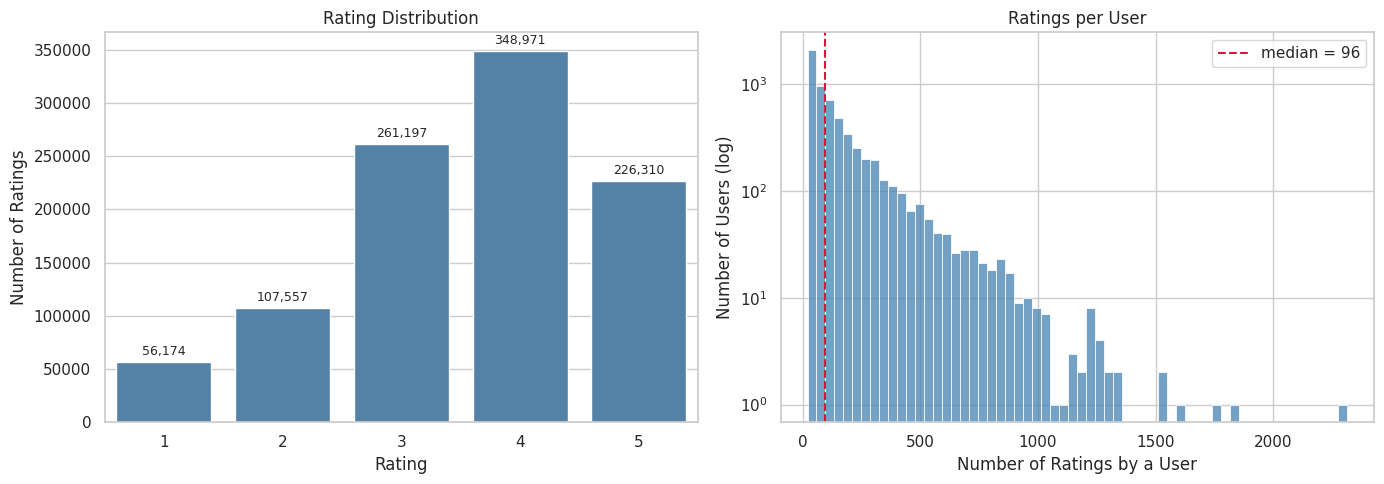

In [5]:
user_counts = ratings.groupby("UserID").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="Rating", color="steelblue", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", padding=3, fontsize=9)
axes[0].set_title("Rating Distribution")
axes[0].set_ylabel("Number of Ratings")

sns.histplot(user_counts, bins=60, color="steelblue", ax=axes[1])
axes[1].set_yscale("log")
axes[1].axvline(user_counts.median(), color="crimson", ls="--", label=f"median = {user_counts.median():.0f}")
axes[1].set_title("Ratings per User")
axes[1].set_xlabel("Number of Ratings by a User")
axes[1].set_ylabel("Number of Users (log)")
axes[1].legend()

plt.tight_layout()
save_fig("00_data_overview")
plt.show()

## 2. 영화 산업 트렌드 (영화 단위)
이 절은 평점 데이터가 아닌 **영화 테이블(3,883편)** 기준으로 집계한다.

### Fig 1. 장르별 영화 수
Drama·Comedy가 압도적으로 많고 Film-Noir·Western·Fantasy는 희소하다. (한 영화가 여러 장르에 속하므로 합계는 영화 수보다 크다)

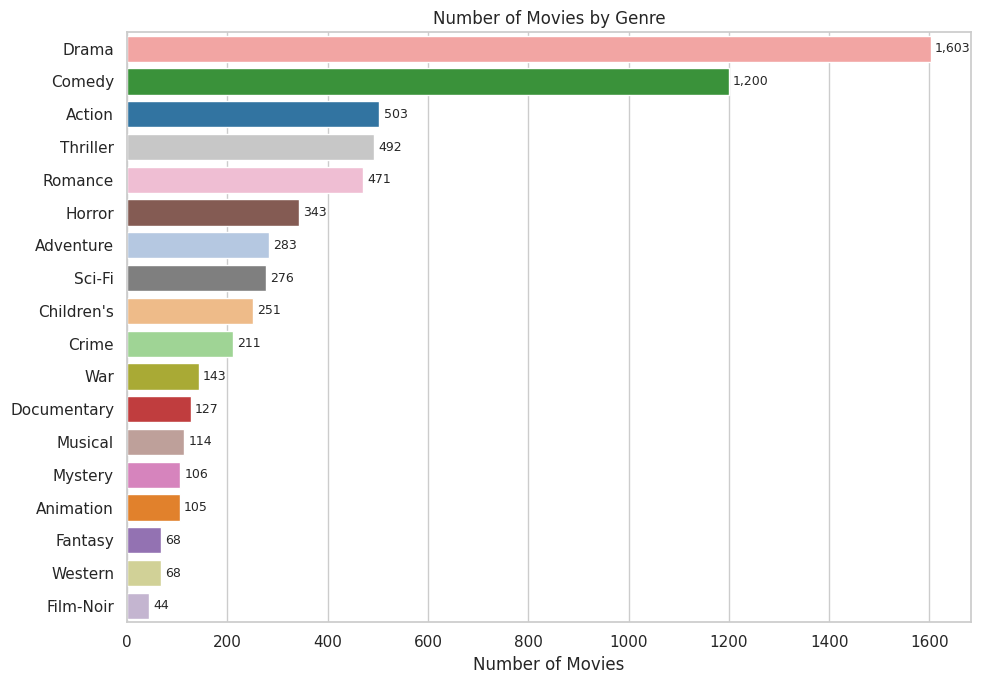

In [6]:
genre_counts = movies_exploded["Genre"].value_counts().reset_index()
genre_counts.columns = ["Genre", "MovieCount"]

plt.figure(figsize=(10, 7))
ax = sns.barplot(data=genre_counts, x="MovieCount", y="Genre", hue="Genre",
                 palette=GENRE_COLORS, legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)
plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("")
plt.tight_layout()
save_fig("01_genre_movie_count")
plt.show()

### Fig 2. 연도별 개봉 영화 수
1980년대 이후 개봉 수가 급증한다. 2000년은 데이터 수집 시점(2000년) 때문에 연도가 끝나지 않아 낮게 나타난다.

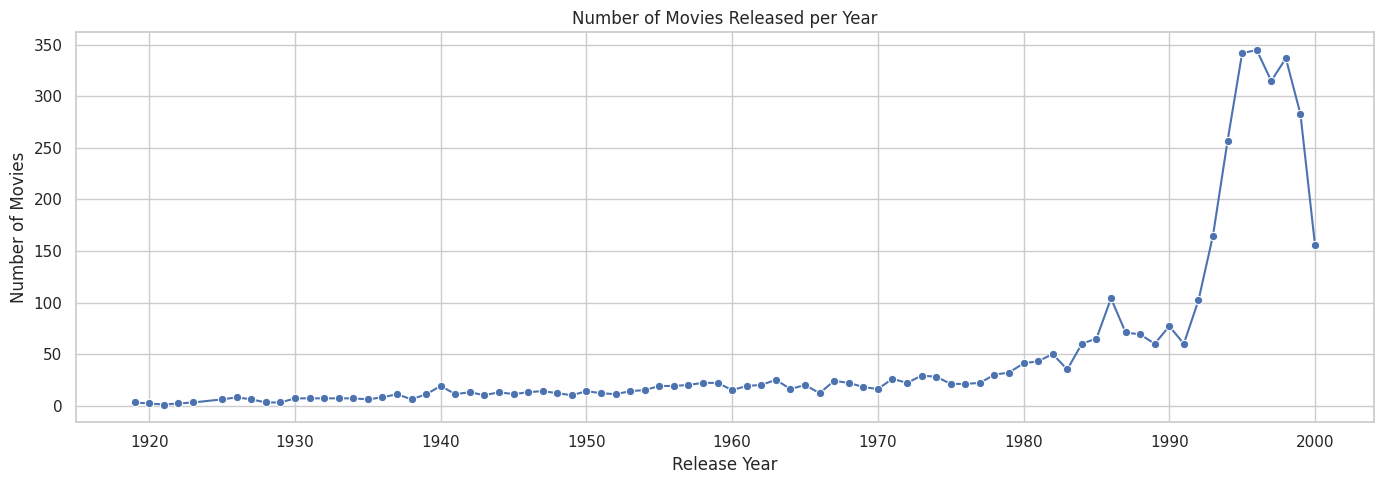

In [7]:
yearly = (movies.dropna(subset=["Year"]).astype({"Year": int})
          .groupby("Year").size().reset_index(name="MovieCount"))

plt.figure(figsize=(14, 5))
sns.lineplot(data=yearly, x="Year", y="MovieCount", marker="o")
plt.title("Number of Movies Released per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
save_fig("02_movies_per_year")
plt.show()

### Fig 3. 상위 5개 장르의 연도별 개봉 추이 (1960년 이후)
1990년대 중반 이후 Drama(연 150편 이상)·Comedy(연 100편 이상)의 증가폭이 가장 크고, Action·Thriller·Romance는 연 50편 안팎으로 비슷한 수준이다.

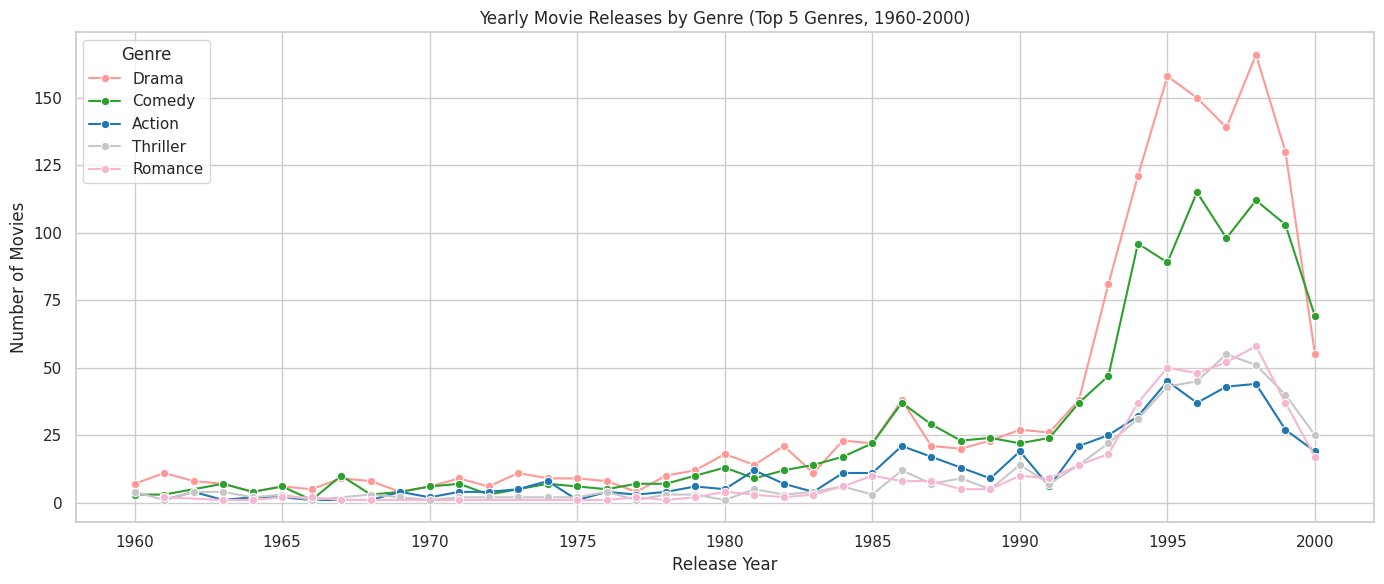

In [8]:
top5_genres = genre_counts["Genre"].head(5).tolist()
genre_year = (movies_exploded.dropna(subset=["Year"]).astype({"Year": int})
              .query("Genre in @top5_genres and Year >= 1960")
              .groupby(["Year", "Genre"]).size().reset_index(name="MovieCount"))

plt.figure(figsize=(14, 6))
sns.lineplot(data=genre_year, x="Year", y="MovieCount", hue="Genre",
             hue_order=top5_genres, palette=GENRE_COLORS, marker="o")
plt.title("Yearly Movie Releases by Genre (Top 5 Genres, 1960-2000)")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.legend(title="Genre")
plt.tight_layout()
save_fig("03_top5_genre_trend")
plt.show()

#

### Fig 4. 장르별 평균 평점
개봉 수가 많은 Comedy·Action은 평점이 중하위권이고, 개봉 수가 적은 Film-Noir·Documentary·War가 평점이 높다. Horror는 유일하게 전체 평균보다 크게 낮다.

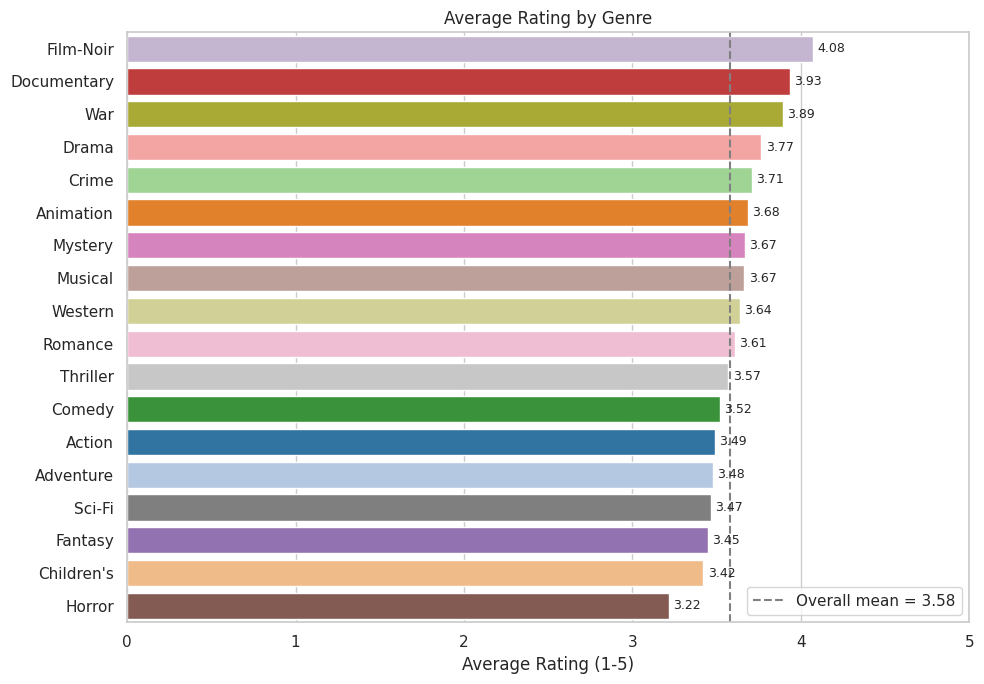

In [9]:
genre_rating = (df_exploded.groupby("Genre")["Rating"]
                .agg(AvgRating="mean", NumRatings="size")
                .sort_values("AvgRating", ascending=False)
                .reset_index())
overall_mean = df["Rating"].mean()

plt.figure(figsize=(10, 7))
ax = sns.barplot(data=genre_rating, x="AvgRating", y="Genre", hue="Genre",
                 palette=GENRE_COLORS, legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
ax.axvline(overall_mean, color="gray", ls="--", label=f"Overall mean = {overall_mean:.2f}")
ax.set_xlim(0, 5)
ax.legend(loc="lower right")
plt.title("Average Rating by Genre")
plt.xlabel("Average Rating (1-5)")
plt.ylabel("")
plt.tight_layout()
save_fig("04_genre_avg_rating")
plt.show()

### Fig 5. 장르별 영화 수 vs 평균 평점
많이 만들어지는 장르가 평점도 높은지 직접 비교한다. Spearman 상관계수는 -0.32로 오히려 약한 음(-)의 관계이며, 영화 수가 적은 Film-Noir·Documentary·War가 평점 상위, 영화 수가 많은 Comedy·Action이 평점 하위에 놓여 **"양"과 "질"은 별개**임을 보여준다.

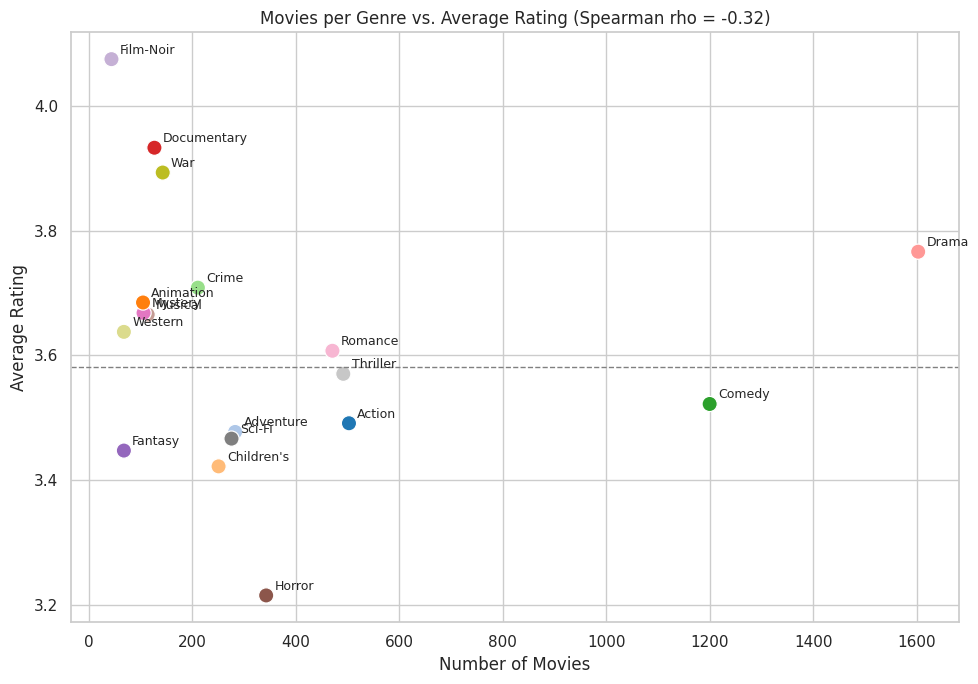

In [10]:
genre_stats = genre_counts.merge(genre_rating, on="Genre")
rho = genre_stats[["MovieCount", "AvgRating"]].corr(method="spearman").iloc[0, 1]

plt.figure(figsize=(10, 7))
ax = sns.scatterplot(data=genre_stats, x="MovieCount", y="AvgRating", hue="Genre",
                     palette=GENRE_COLORS, s=120, legend=False)
for _, row in genre_stats.iterrows():
    ax.annotate(row["Genre"], (row["MovieCount"], row["AvgRating"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.axhline(overall_mean, color="gray", ls="--", lw=1)
plt.title(f"Movies per Genre vs. Average Rating (Spearman rho = {rho:.2f})")
plt.xlabel("Number of Movies")
plt.ylabel("Average Rating")
plt.tight_layout()
save_fig("05_genre_count_vs_rating")
plt.show()

### Fig 6. 성별 × 장르 평균 평점 히트맵
왼쪽은 성별 평균 평점, 오른쪽은 여성-남성 차이. Children's·Musical(+0.21)·Romance(+0.10)는 여성이, Western(-0.10)·Film-Noir(-0.07)은 남성이 상대적으로 높게 평가하며, Drama·War·Action·Thriller는 성별 차이가 거의 없다.

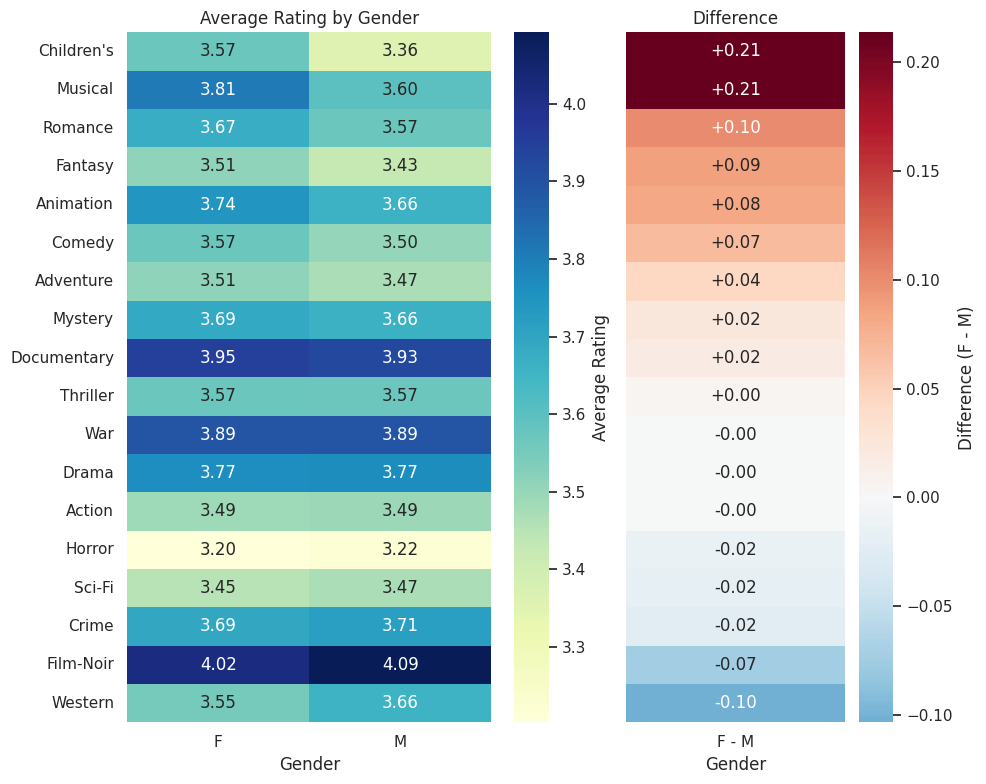

In [11]:
gender_genre_rating = df_exploded.pivot_table(index="Genre", columns="Gender",
                                              values="Rating", aggfunc="mean")
gender_genre_rating["F - M"] = gender_genre_rating["F"] - gender_genre_rating["M"]
gender_genre_rating = gender_genre_rating.sort_values("F - M", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 8), gridspec_kw={"width_ratios": [2, 1.2]})
sns.heatmap(gender_genre_rating[["F", "M"]], annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "Average Rating"}, ax=axes[0])
axes[0].set_title("Average Rating by Gender")
axes[0].set_ylabel("")
sns.heatmap(gender_genre_rating[["F - M"]], annot=True, fmt="+.2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Difference (F - M)"}, ax=axes[1])
axes[1].set_title("Difference")
axes[1].set_ylabel("")
axes[1].set_yticks([])
plt.tight_layout()
save_fig("06_gender_genre_rating_heatmap")
plt.show()

## 4. 유저 집단별 선호 장르
남성 유저(4,331명)가 여성(1,709명)보다 2.5배 많고 나이대·직업도 인원이 다르므로, 절대 건수가 아니라 **집단 내 시청 비율**(해당 집단 평점 중 그 장르가 차지하는 비율)로 비교한다.

In [12]:
def genre_ratio(frame: pd.DataFrame, group_col: str) -> pd.DataFrame:
    """집단(group_col)별 장르 시청 건수와 집단 내 비율."""
    counts = frame.groupby([group_col, "Genre"], observed=True).size().reset_index(name="Count")
    counts["Ratio"] = counts["Count"] / counts.groupby(group_col, observed=True)["Count"].transform("sum")
    return counts


top10_genres = df_exploded["Genre"].value_counts().head(10).index.tolist()
gender_ratio = genre_ratio(df_exploded, "Gender")
age_ratio = genre_ratio(df_exploded, "AgeGroup")
occupation_ratio = genre_ratio(df_exploded, "OccupationLabel")

### Fig 7. 성별 장르 시청 비율 (상위 10개 장르)
여성은 Drama·Romance·Comedy, 남성은 Action·Sci-Fi·Thriller 비중이 높다.

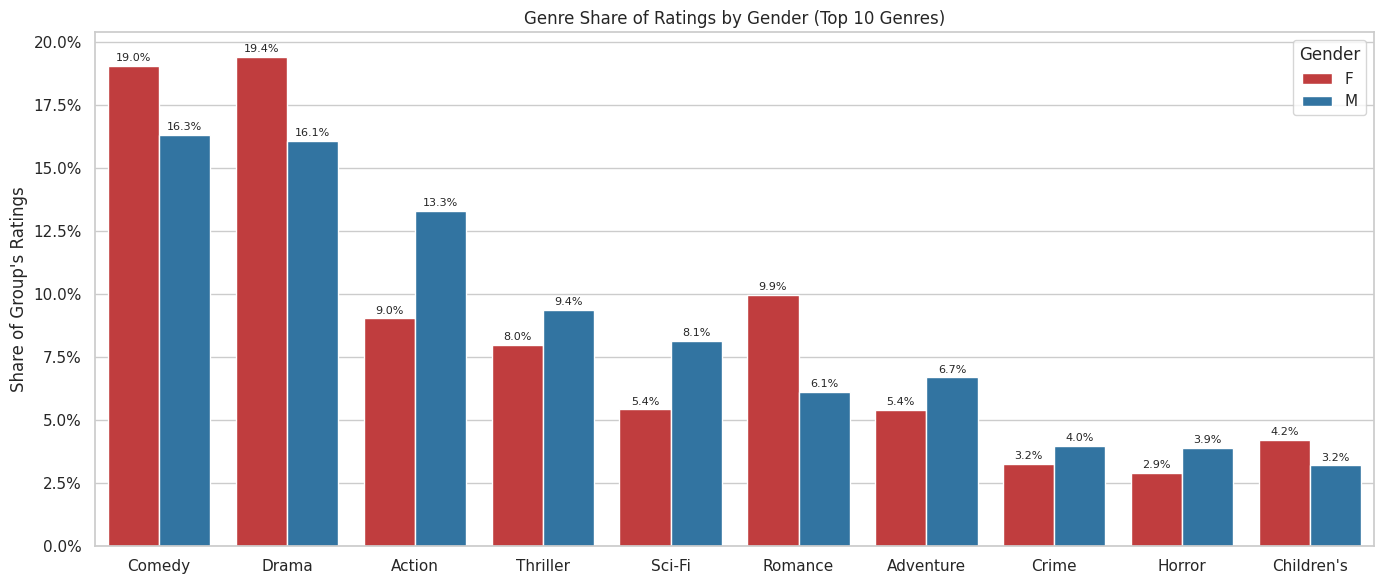

In [13]:
plt.figure(figsize=(14, 6))
ax = sns.barplot(data=gender_ratio[gender_ratio["Genre"].isin(top10_genres)],
                 x="Genre", y="Ratio", hue="Gender", order=top10_genres,
                 palette={"F": "#d62728", "M": "#1f77b4"})
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
for container in ax.containers:
    ax.bar_label(container, fmt="{:.1%}", padding=2, fontsize=8)
plt.title("Genre Share of Ratings by Gender (Top 10 Genres)")
plt.xlabel("")
plt.ylabel("Share of Group's Ratings")
plt.legend(title="Gender")
plt.tight_layout()
save_fig("07_gender_genre_ratio")
plt.show()

### Fig 8. 나이대 × 장르 시청 비율 히트맵
18세 미만은 Children's(7.4%)·Animation(4.2%) 비중이 다른 나이대의 2~3배이고, 나이가 많아질수록 Drama(12.7% → 21.9%)·War·Romance·Film-Noir 비중이 꾸준히 커지는 반면 Comedy(19.0% → 15.2%)·Action·Horror는 줄어 나이대에 따른 선호 이동이 뚜렷하다.

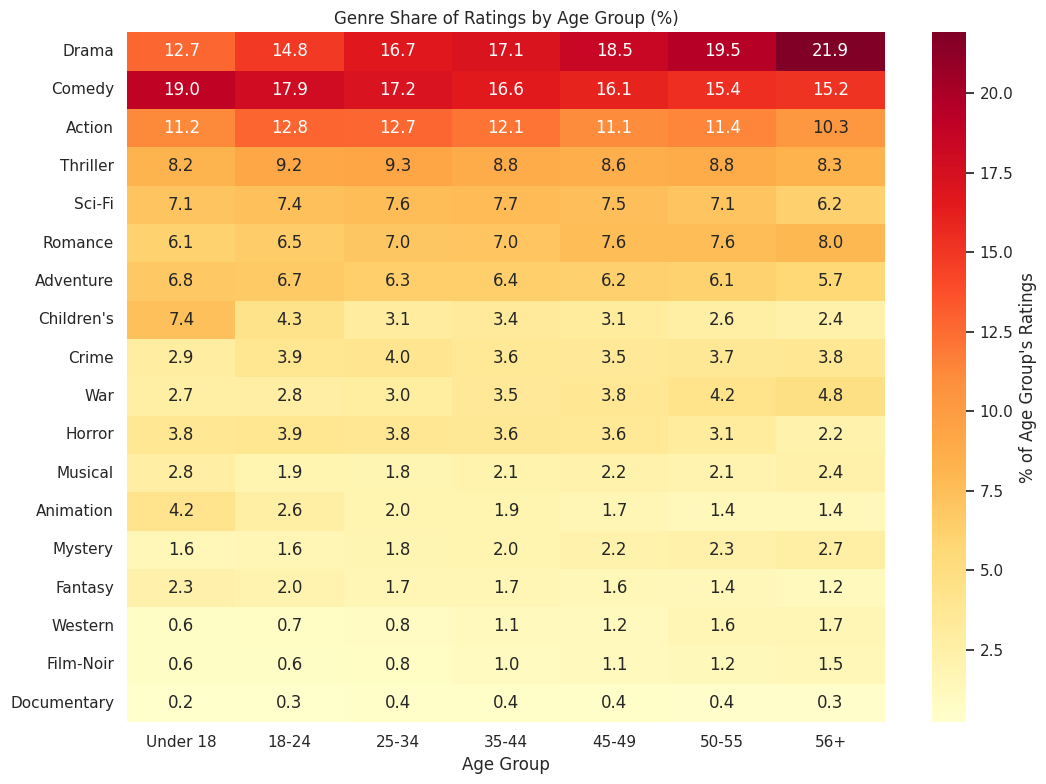

In [14]:
age_pivot = (age_ratio.pivot(index="Genre", columns="AgeGroup", values="Ratio")
             .reindex(columns=AGE_ORDER))
age_pivot = age_pivot.loc[age_pivot.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(11, 8))
sns.heatmap(age_pivot * 100, annot=True, fmt=".1f", cmap="YlOrRd",
            cbar_kws={"label": "% of Age Group's Ratings"})
plt.title("Genre Share of Ratings by Age Group (%)")
plt.xlabel("Age Group")
plt.ylabel("")
plt.tight_layout()
save_fig("08_age_genre_ratio_heatmap")
plt.show()

### Fig 9. 성별·나이대별 상위 5개 장르 비율 파이차트
장르별 고정 색상, 비율 내림차순 정렬, 상위 5개 외는 Others로 묶고 상위 3개만 분리(explode)해 집단 간 비교가 쉽도록 했다.
모든 집단에서 Drama·Comedy가 1~2위, Action·Thriller가 3~4위로 공통이지만, 5번째 장르가 여성·45세 이상은 Romance, 남성·18~44세는 Sci-Fi, 18세 미만은 Children's로 갈려 집단 정보만으로도 초기 추천 장르를 구분할 수 있다.

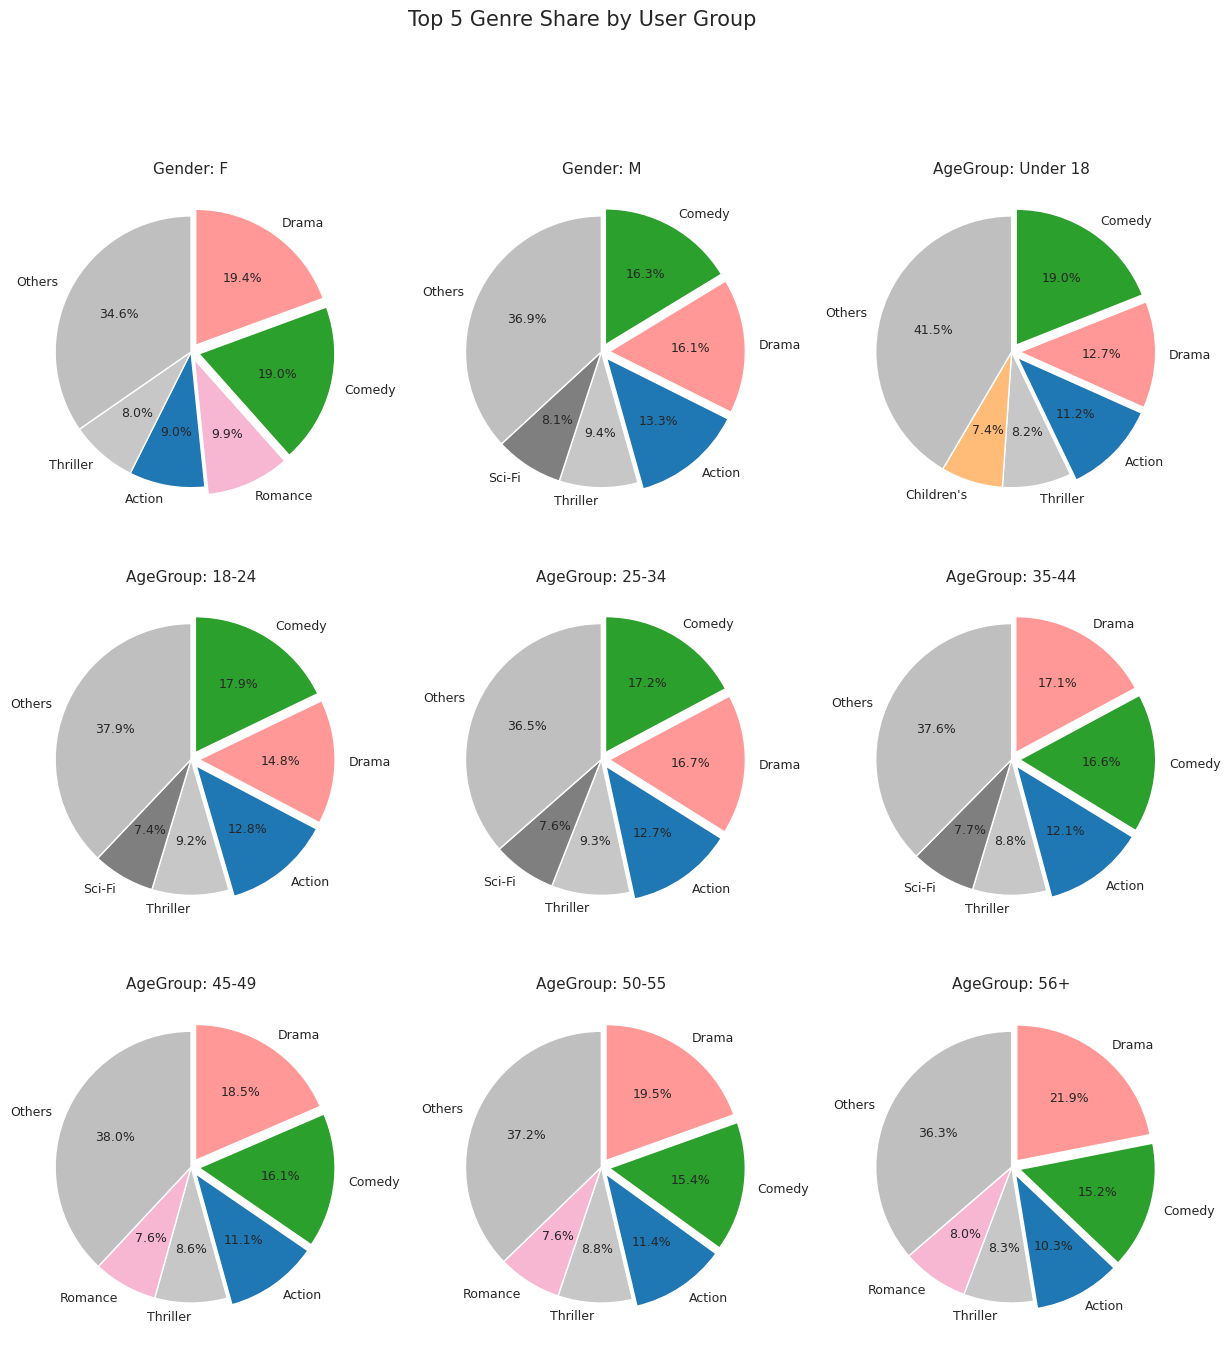

In [15]:
def top_n_with_others(ratio_frame: pd.DataFrame, group_col: str, group, n: int = 5) -> pd.Series:
    share = (ratio_frame.loc[ratio_frame[group_col] == group]
             .set_index("Genre")["Ratio"].sort_values(ascending=False))
    return pd.concat([share.iloc[:n], pd.Series({"Others": share.iloc[n:].sum()})])


def draw_pie(ax, data: pd.Series, title: str) -> None:
    colors = [GENRE_COLORS.get(label, "#cccccc") for label in data.index]
    explode = [0.06 if i < 3 else 0 for i in range(len(data))]
    ax.pie(data.values, labels=data.index, colors=colors, explode=explode,
           autopct="%1.1f%%", startangle=90, counterclock=False,
           textprops={"fontsize": 9}, wedgeprops={"edgecolor": "white"})
    ax.set_title(title, fontsize=11)


groups = [("Gender", g) for g in ["F", "M"]] + [("AgeGroup", a) for a in AGE_ORDER]
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (col, group) in zip(axes.flat, groups):
    frame = gender_ratio if col == "Gender" else age_ratio
    draw_pie(ax, top_n_with_others(frame, col, group), f"{col}: {group}")
fig.suptitle("Top 5 Genre Share by User Group", fontsize=15, y=0.995)
save_fig("09_top5_genre_pie_by_group")
plt.show()

### Fig 10. 직업별 선호 장르 (전체 평균 대비 차이)
직업별 시청 비율에서 전체 평균 비율을 뺀 값(%p). 양수(빨강)는 그 직업이 평균보다 더 보는 장르.
직업에 따른 차이는 대부분 ±2%p 이내로 성별·나이대보다 작지만, 일부 직업은 뚜렷하다: retired의 Drama(+5.1%p), K-12 student의 Children's(+4.2%p, Drama -5.1%p), homemaker의 Comedy(+4.3%p)·Romance(+4.2%p), programmer/technician의 Sci-Fi(+2%p 이상), tradesman의 Horror(+3.2%p).

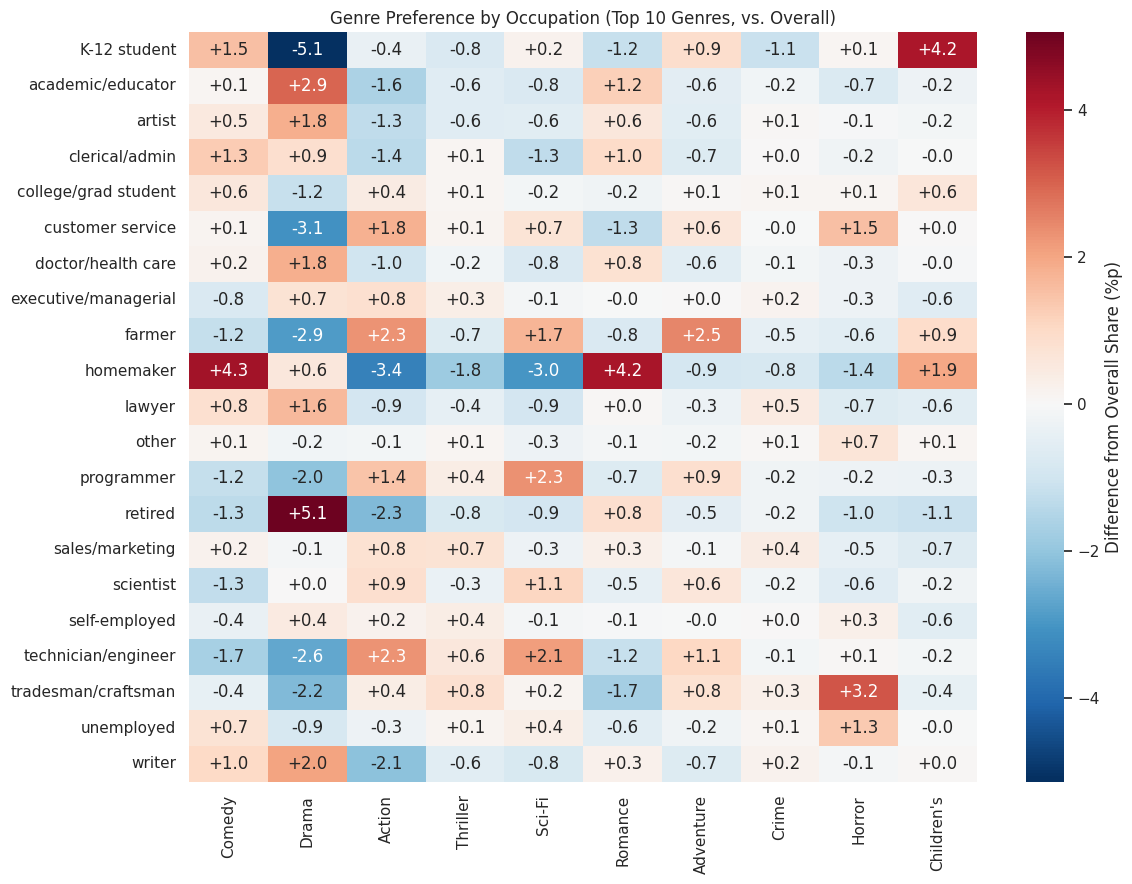

In [16]:
overall_share = df_exploded["Genre"].value_counts(normalize=True)
occupation_pivot = (occupation_ratio[occupation_ratio["Genre"].isin(top10_genres)]
                    .pivot(index="OccupationLabel", columns="Genre", values="Ratio")[top10_genres])
occupation_diff = (occupation_pivot - overall_share[top10_genres]) * 100

plt.figure(figsize=(12, 9))
sns.heatmap(occupation_diff, annot=True, fmt="+.1f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Difference from Overall Share (%p)"})
plt.title("Genre Preference by Occupation (Top 10 Genres, vs. Overall)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
save_fig("10_occupation_genre_heatmap")
plt.show()

## 5. 결론

- **양 ≠ 질**: 영화 수가 많은 장르(Comedy·Action)와 평점이 높은 장르(Film-Noir·Documentary·War)는 다르며, 둘 사이 상관은 오히려 약한 음(-0.32)이다. 추천 시 "인기 장르"와 "만족도 높은 장르"를 구분해야 한다.
- **성별·나이대는 선호 장르를 뚜렷하게 가른다**: 여성은 Romance·Drama·Comedy 시청 비중과 Children's·Musical 평점이 높고, 남성은 Action·Sci-Fi·Thriller 비중이 높다. 18세 미만은 Children's·Animation, 나이가 많을수록 Drama·War·Romance 비중이 커진다.
- **직업은 보조 변수**: 차이는 대부분 ±2%p 이내지만 은퇴자(Drama), 초중고 학생(Children's), 주부(Comedy·Romance), 프로그래머·엔지니어(Sci-Fi) 등 일부 직업에서 뚜렷한 선호가 나타난다.
- 따라서 평점 이력이 없는 신규 유저라도 성별·나이대(+직업)만으로 초기 추천 장르를 정하는 **Cold-start 전략**의 근거로 활용할 수 있다.